# PyTorch World

**Shared infrastructure for world models in PyTorch.** JEPA-style models predict the *representation* of what comes next instead of its pixels. With actions as input they become world models you can plan with.

`torch_world` gives them common parts: transformers and masked predictors (`nn`), masking strategies (`masks`), objectives (`losses`), planners (`planning`), environments and data (`envs`, `datasets`) and figures (`plots`). A model is a short file built from these parts.

In [1]:
import torch
import torch.nn.functional as F
from torch import nn

from torch_world import plots
from torch_world.envs import Macaw, run_policy
from torch_world.masks import MultiBlock3DMask, MultiBlockMask
from torch_world.models import DINOWM, IJEPA, VJEPA, LeJEPA, LeWM, RoboJEPA
from torch_world.nn import MLP, MaskedPredictor, VisionTransformer
from torch_world.planning import CEM

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

## A world to model
`Macaw` is a batched pixel world: a Hyacinth macaw flying over the Pantanal, steered by velocity actions. Its wings beat a quarter cycle per step, so a model has to read the motion from a few frames. Models see 64×64 frames; the figures draw the same states at 192×192.

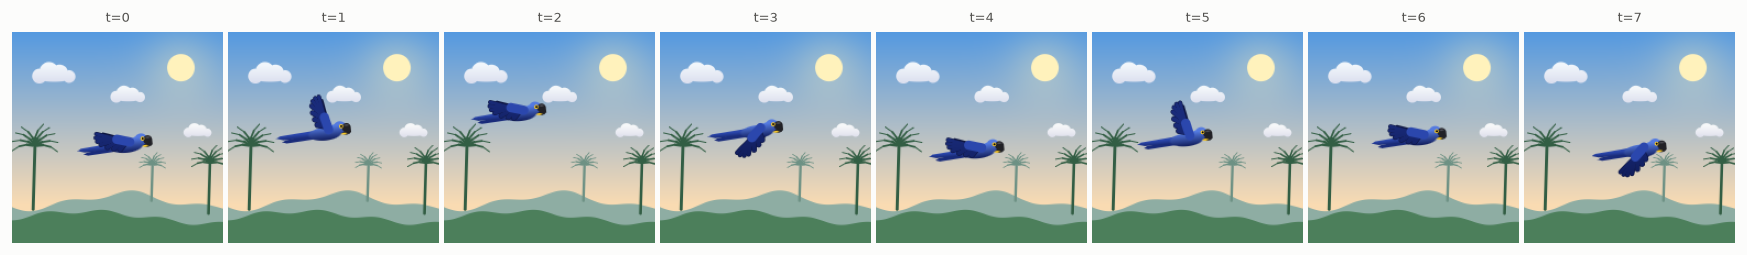

In [2]:
episode = Macaw(batch_size=1).collect(8, generator=torch.Generator().manual_seed(4))
HD = Macaw(size=192)
beat = lambda n: torch.arange(n) * torch.pi / 2
plots.images(HD.render(episode["states"][0], beat(8)), [f"t={t}" for t in range(8)], size=1.8)

## Masks: what to predict
I-JEPA hides image blocks; V-JEPA hides spatio-temporal tubes.

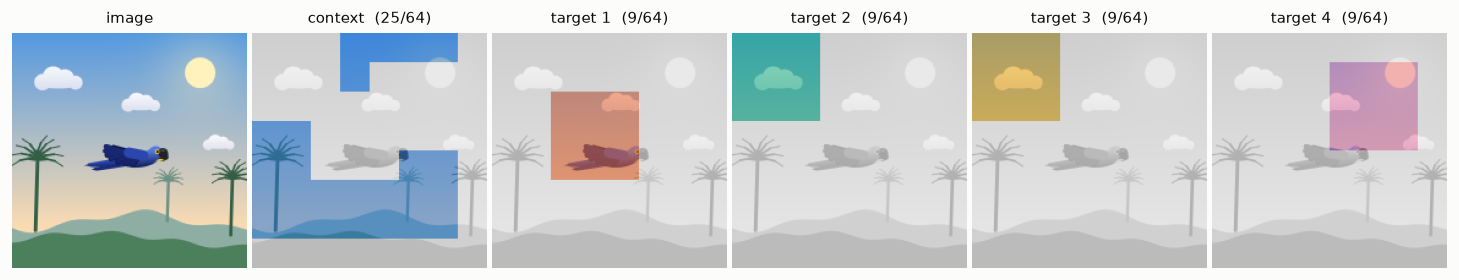

In [3]:
image = HD.render(episode["states"][0, :1])[0]
masks_enc, masks_pred = MultiBlockMask((8, 8), min_keep=4)(1, generator=torch.Generator().manual_seed(3))
plots.masks(image, (8, 8), {"context": masks_enc[0][0], **{f"target {i + 1}": m[0] for i, m in enumerate(masks_pred)}})

## One interface, many models
Every JEPA returns a dict with `loss`, and every world model also has `encode`, `predict` and `rollout`.

In [4]:
vit = lambda **kw: VisionTransformer(img_size=64, patch_size=16, embed_dim=64, depth=2, num_heads=4, **kw)


class CLS(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = vit(cls_token=True)

    def forward(self, x):
        return self.vit(x)[:, 0]


class Patches(nn.Module):
    def __init__(self, size=16):
        super().__init__()
        self.size = size

    def forward(self, x):
        return F.pixel_unshuffle(x, self.size).flatten(2).transpose(1, 2)


data = Macaw(batch_size=16).collect(4)
pixels, actions, states = data["pixels"], data["actions"], data["states"]
video = Macaw(batch_size=16).collect(4)["pixels"].transpose(1, 2)
encoder, video_encoder = vit(), vit(num_frames=4)
masks_2d = MultiBlockMask(encoder.grid, min_keep=0)(16)
[enc_3d], [pred_3d] = MultiBlock3DMask(video_encoder.grid, num_blocks=2)(16)

models = {
    "I-JEPA": (IJEPA(encoder, MaskedPredictor(encoder.grid, 64, 32, depth=1, num_heads=4)), (pixels[:, 0], *masks_2d)),
    "V-JEPA": (VJEPA(video_encoder, MaskedPredictor(video_encoder.grid, 64, 32, depth=1, num_heads=4)), (video, [enc_3d], [pred_3d])),
    "LeJEPA": (LeJEPA(CLS(), MLP([64, 128, 32], norm=nn.BatchNorm1d)), (pixels,)),
    "LeWM": (LeWM(CLS(), action_dim=2, embed_dim=64, depth=2, num_heads=4, head_dim=16, mlp_dim=128, proj_dim=128), (pixels, actions)),
    "DINO-WM": (DINOWM(Patches(), num_patches=16, embed_dim=768, action_dim=2, proprio_dim=2, depth=2, num_heads=4, head_dim=16, mlp_dim=128), (pixels, actions, states)),
    "RoboJEPA": (RoboJEPA(embed_dim=768, action_dim=2, state_dim=2, depth=2, num_heads=4, predictor_dim=64), (Patches()(pixels.flatten(0, 1)).view(16, 4, 1, 4, 4, 768), actions, states)),
}
for name, (model, inputs) in models.items():
    loss = model(*inputs)["loss"]
    print(f"{name:9s} {sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6:5.2f}M trainable   loss {loss.item():.3f}")

I-JEPA     0.17M trainable   loss 0.442
V-JEPA     0.22M trainable   loss 0.832
LeJEPA     0.16M trainable   loss 0.304


LeWM       0.32M trainable   loss 0.709
DINO-WM    0.86M trainable   loss 1.402
RoboJEPA   0.20M trainable   loss 1.868


## Train a world model and plan with it
DINO-WM learns dynamics on frozen features (raw pixel patches here). CEM then plans in that feature space toward goal images.

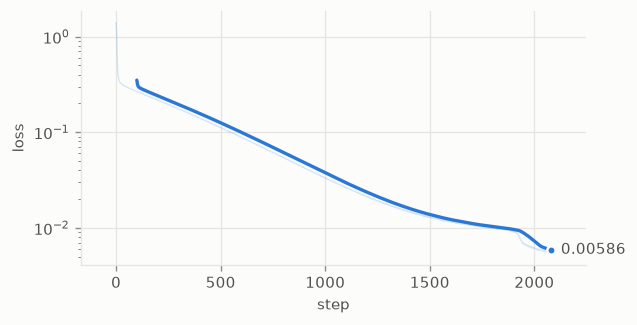

In [5]:
from torch.utils.data import DataLoader

from torch_world.datasets import TrajectoryDataset

model = DINOWM(Patches(16), num_patches=16, embed_dim=768, action_dim=2, proprio_dim=2, depth=4, num_heads=8, head_dim=32, mlp_dim=512).to(device)
data = {k: v.to(device) for k, v in Macaw(batch_size=4096).collect(16).items()}
opt = torch.optim.AdamW(model.parameters(), lr=5e-4)
log = {"prediction": []}
for epoch in range(10):
    for batch in DataLoader(TrajectoryDataset(data, 4), batch_size=256, shuffle=True, drop_last=True):
        loss = model(batch["pixels"], batch["actions"], batch["states"])["loss"]
        opt.zero_grad()
        loss.backward()
        opt.step()
        log["prediction"].append(loss.item())
model.eval()
plots.curves(log, smooth=100)

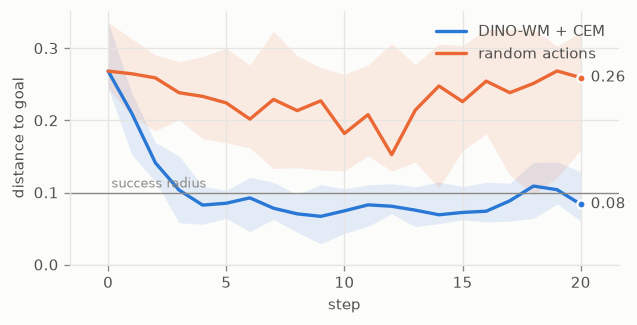

In [6]:
env = Macaw(batch_size=16, device=device)
env.reset(generator=torch.Generator().manual_seed(1))
start, goals = env.state.clone(), env.sample_goals((0.2, 0.5), generator=torch.Generator().manual_seed(2))
planner = CEM(horizon=5, action_dim=2, num_samples=256, num_elites=32, iterations=10, bounds=(-1, 1))
with torch.no_grad():
    goal = model.encode(env.render(goals)[:, None], goals[:, None])[:, 0]

paths = run_policy(env, lambda obs: planner(model, model.encode(obs[:, None], env.state[:, None]), goal)[:, 0], steps=20)
env.reset(start)
random = run_policy(env, lambda obs: torch.rand(len(obs), 2, device=device) * 2 - 1, steps=20)
distance = lambda p: (p - goals[:, None]).norm(dim=-1)
plots.distances({"DINO-WM + CEM": distance(paths), "random actions": distance(random)}, radius=0.1)

The macaw's flight toward the goal image (last panel):

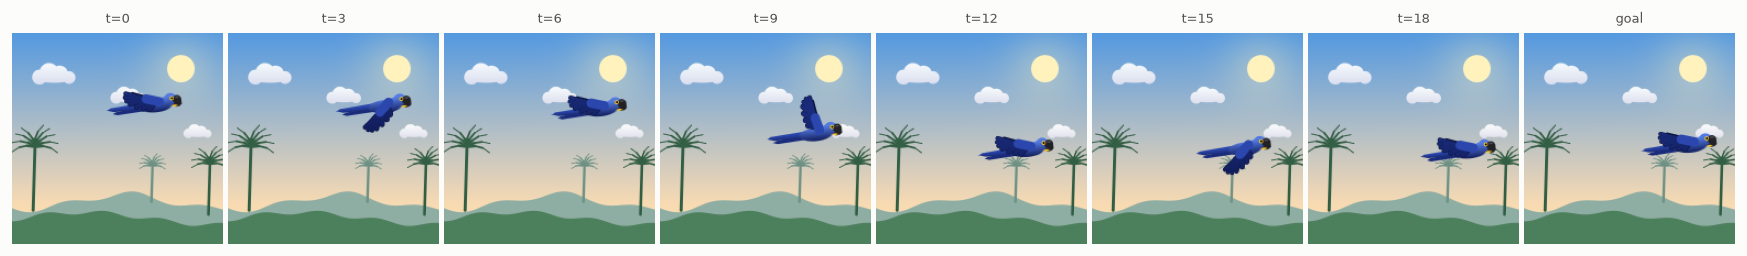

In [7]:
keep = torch.arange(0, 21, 3)
flight = HD.render(paths[0, keep].cpu(), beat(21)[keep])
plots.images(torch.cat([flight, HD.render(goals[:1].cpu())]), [f"t={t}" for t in keep.tolist()] + ["goal"], size=1.8)

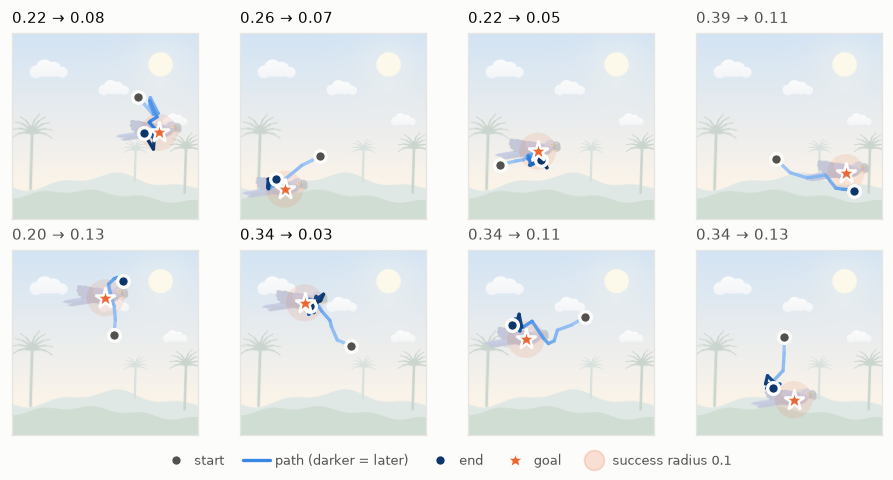

In [8]:
plots.trajectories(paths[:8], goals[:8], background=Macaw(batch_size=8, size=192).render(goals[:8].cpu()))

## Where next

| notebook | model |
|---|---|
| [vision/ijepa](vision/ijepa.ipynb) | I-JEPA: masked image modeling in feature space |
| [vision/vjepa](vision/vjepa.ipynb) | V-JEPA / V-JEPA 2: masked video modeling |
| [vision/lejepa](vision/lejepa.ipynb) | LeJEPA: SIGReg, no teacher, no stop-gradient |
| [vqa/vljepa](vqa/vljepa.ipynb) | VL-JEPA: answering by predicting embeddings |
| [action/lewm](action/lewm.ipynb) | LeWM: an end-to-end world model from pixels |
| [action/dinowm](action/dinowm.ipynb) | DINO-WM: a world model on frozen features |
| [action/robojepa](action/robojepa.ipynb) | RoboJEPA: one model for many embodiments |
| [custom_model](custom_model.ipynb) | build your own world model |